# Trabajo Práctico — Análisis de un Dataset

## Fundamentos de Aprendizaje Automático · 2026

**Docente:** Prof. Ramón F. López-Imizcoz

**Modalidad:** individual o en equipo (se sugiere no más de 2 integrantes)

**Entrega:** este mismo notebook de Google Colab, completado y ejecutado.

---

### Objetivo

El objetivo de este trabajo es **simple pero completo**: elegir un dataset, identificar correctamente el **tipo de datos** que contiene, aplicar las **herramientas de análisis adecuadas** para ese tipo de datos, y razonar sobre **qué modelo** se podría construir y **para qué uso** concreto.

No se busca aquí entrenar un modelo complejo ni alcanzar una métrica óptima. Se busca que demuestren que entienden el **flujo de razonamiento** que va desde los datos hasta una decisión de modelado fundamentada.

> **Sugerencia de uso:** ejecuten celda por celda. Antes de ejecutar una celda de código, pregúntense *"¿qué espero ver como salida?"* y recién después comparen con el resultado real.


# 1. Consigna

A lo largo de este notebook deberán completar las siguientes **cinco etapas**:

1. **Elección del dataset.** Seleccionar un conjunto de datos y justificar brevemente por qué les interesa.
2. **Identificación del tipo de datos.** Determinar qué tipo de variables contiene (numéricas, categóricas, temporales, texto, etc.) y si hay o no una variable objetivo (*target*).
3. **Análisis exploratorio (EDA).** Aplicar las herramientas de análisis **adecuadas al tipo de datos** identificado: estadísticos descriptivos, visualizaciones, correlaciones, conteos, etc.
4. **Propuesta de modelo.** Indicar qué **tipo de modelo** se podría construir (clasificación, regresión, agrupamiento/*clustering*, etc.) y por qué ese tipo es el correcto para estos datos.
5. **Uso previsto.** Explicar **para qué** y **para quién** se construiría ese modelo: qué decisión ayudaría a tomar y en qué contexto.

Cada etapa tiene su propia sección más abajo, con celdas de texto para sus respuestas y celdas de código para el análisis.


# 2. Recordatorio: tipos de datos y herramientas asociadas

Antes de empezar, conviene recordar la relación entre el **tipo de dato** y la **herramienta de análisis** apropiada. Esta tabla es su brújula durante el trabajo:

| Tipo de variable | Ejemplos | Análisis exploratorio típico | Modelos asociados |
|---|---|---|---|
| **Numérica continua** | precio, edad, temperatura | histograma, media/mediana/desvío, correlación | regresión, clustering |
| **Numérica discreta** | cantidad de hijos, n.º de visitas | conteos, histograma | regresión, clasificación |
| **Categórica nominal** | país, color, marca | tabla de frecuencias, gráfico de barras | clasificación |
| **Categórica ordinal** | nivel educativo, satisfacción (bajo/medio/alto) | barras, conteos ordenados | clasificación, regresión ordinal |
| **Temporal** | fecha, hora, timestamp | serie temporal, tendencia/estacionalidad | series de tiempo, forecasting |
| **Texto** | reseñas, comentarios | longitud, palabras frecuentes | NLP, clasificación de texto |

> **Idea clave:** la herramienta de análisis **no se elige al azar**: se deriva del tipo de dato. Un histograma tiene sentido para una variable numérica; una tabla de frecuencias, para una categórica.


# 3. Preparación del entorno

Ejecuten esta celda primero. Importa las librerías estándar que usaremos: `pandas` para manipular tablas, `numpy` para cálculo numérico, y `matplotlib`/`seaborn` para visualizar.


In [1]:
# Importamos las librerías de trabajo
import pandas as pd          # manipulación de datos en tablas (DataFrames)
import numpy as np           # cálculo numérico
import matplotlib.pyplot as plt  # gráficos
import seaborn as sns        # gráficos estadísticos de alto nivel

# Configuración estética de los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

print("Entorno listo. Versiones:")
print("pandas :", pd.__version__)
print("numpy  :", np.__version__)


Entorno listo. Versiones:
pandas : 3.1.1
numpy  : 2.5.5


# Etapa 1 — Elección del dataset

Elijan **un** dataset. Tienen tres caminos posibles:

**Opción A — Dataset incorporado en seaborn (lo más simple).**
Por ejemplo: `tips`, `titanic`, `penguins`, `iris`, `diamonds`, `flights`.

**Opción B — Subir un archivo CSV propio.**
Usen el panel de archivos de Colab (ícono de carpeta a la izquierda) o la celda de carga de más abajo.

**Opción C — Desde una URL pública** (un CSV accesible por internet).

Completen la celda de código según la opción elegida. Dejen **descomentada solo una** de las tres opciones.


In [2]:
# === Opción A: dataset incorporado en seaborn ===
# df = sns.load_dataset("penguins")

# === Opción B (elegida): CSV propio ===
# Se busca primero la ruta local (ejecución desde la raíz del repositorio).
# Si el archivo no está y el notebook corre en Google Colab, se ofrece subirlo.
from pathlib import Path

ruta_csv = Path("data/alb-request-count-hourly-since-2026-05-01.csv")

if not ruta_csv.exists():
    try:
        from google.colab import files   # solo existe en Colab
        subido = files.upload()          # abre el diálogo de carga
        ruta_csv = Path(list(subido.keys())[0])
    except ImportError:
        raise FileNotFoundError(f"No se encontró el CSV en {ruta_csv.resolve()}. "
                                "Ejecuten el notebook desde la raíz del repositorio.")

columnas_fecha = ["period_start_utc", "period_end_utc"]
df = pd.read_csv(ruta_csv, parse_dates=columnas_fecha)
for col in columnas_fecha:
    df[col] = pd.to_datetime(df[col], utc=True)   # los timestamps vienen en UTC (sufijo Z)

# === Opción C: leer un CSV desde una URL pública ===
# url = "https://ejemplo.com/mi_dataset.csv"
# df = pd.read_csv(url)

# Vistazo inicial
print("Archivo:", ruta_csv.name)
df.head()

Archivo: alb-request-count-hourly-since-2026-05-01.csv


,load_balancer,target_group,metric_name,period_start_utc,period_end_utc,value
0,app/bodegaai-production-alb/31b69d3d76ab5ed1,NaN,RequestCount,2026-05-01 00:00:00+00:00,2026-05-01 01:00:00+00:00,0
1,app/bodegaai-production-alb/31b69d3d76ab5ed1,NaN,RequestCount,2026-05-01 01:00:00+00:00,2026-05-01 02:00:00+00:00,0
2,app/bodegaai-production-alb/31b69d3d76ab5ed1,NaN,RequestCount,2026-05-01 02:00:00+00:00,2026-05-01 03:00:00+00:00,0
3,app/bodegaai-production-alb/31b69d3d76ab5ed1,NaN,RequestCount,2026-05-01 03:00:00+00:00,2026-05-01 04:00:00+00:00,0
4,app/bodegaai-production-alb/31b69d3d76ab5ed1,NaN,RequestCount,2026-05-01 04:00:00+00:00,2026-05-01 05:00:00+00:00,0


### ✏️ Su respuesta — Etapa 1

> **Nota:** este notebook es una variante del TP principal (`TP_Analisis_de_Dataset_v3.ipynb`). Aplica el mismo flujo de análisis a otra métrica del mismo sistema.

**Dataset elegido:** `alb-request-count-hourly-since-2026-05-01.csv` (carpeta `data/` del repositorio). Es la métrica de AWS CloudWatch **`RequestCount`** del *Application Load Balancer* de producción (`bodegaai-production-alb`), exportada a CSV con granularidad **horaria**.

**¿Por qué lo eligieron?** En el TP principal se analizó `RequestCountPerTarget`, un promedio por target sano que cambia cuando el *autoscaling* agrega o quita targets. Allí se concluyó que para planificar capacidad conviene trabajar con el **tráfico total**. Este dataset es justamente ese tráfico total: la cantidad de solicitudes por hora que procesó el balanceador, en 3575 horas consecutivas del 01/05/2026 al 26/09/2026. Permite verificar si las conclusiones del TP se sostienen sobre una variable que no depende de la cantidad de targets.

**Definición de la métrica (AWS):** `RequestCount` es *"the number of requests processed over IPv4 and IPv6"*, contando solo las solicitudes para las que el balanceador pudo elegir un target. El estadístico útil es `Sum`. Este export no tiene dimensión `TargetGroup`, así que cuenta **todo el balanceador**: si el ALB enrutara a otros *target groups* además del servicio de tienda, ese tráfico también estaría incluido. Fuente: [CloudWatch metrics for your Application Load Balancer](https://docs.aws.amazon.com/elasticloadbalancing/latest/application/load-balancer-cloudwatch-metrics.html).

# Etapa 2 — Identificación del tipo de datos

Ahora vamos a inspeccionar la estructura del dataset para entender **qué tipo de variables** contiene.


In [3]:
# Dimensiones del dataset: (filas, columnas)
print("Filas y columnas:", df.shape)
print()

# Tipo de dato que pandas asignó a cada columna
print("Tipos de cada columna:")
print(df.dtypes)


Filas y columnas: (3575, 6)

Tipos de cada columna:
load_balancer                       str
target_group                    float64
metric_name                         str
period_start_utc    datetime64[us, UTC]
period_end_utc      datetime64[us, UTC]
value                             int64
dtype: object


In [4]:
# Resumen general: tipos, valores no nulos y memoria
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 3575 entries, 0 to 3574
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype              
---  ------            --------------  -----              
 0   load_balancer     3575 non-null   str                
 1   target_group      0 non-null      float64            
 2   metric_name       3575 non-null   str                
 3   period_start_utc  3575 non-null   datetime64[us, UTC]
 4   period_end_utc    3575 non-null   datetime64[us, UTC]
 5   value             3575 non-null   int64              
dtypes: datetime64[us, UTC](2), float64(1), int64(1), str(2)
memory usage: 167.7 KB


In [5]:
# ¿Cuántos valores faltantes (NaN) hay por columna?
print("Valores faltantes por columna:")
print(df.isna().sum())


Valores faltantes por columna:
load_balancer          0
target_group        3575
metric_name            0
period_start_utc       0
period_end_utc         0
value                  0
dtype: int64


In [6]:
# Diagnóstico específico de una serie temporal
# 1) ¿Cuántos valores distintos tiene cada columna? (detecta columnas constantes)
print("Valores únicos por columna:")
print(df.nunique())
vacias = [c for c in df.columns if df[c].isna().all()]
print("Columnas completamente vacías:", vacias, "| faltantes:", {c: int(df[c].isna().sum()) for c in vacias})
print()

# 2) Filas duplicadas y duración de cada período
print("Filas duplicadas:", df.duplicated().sum())
print("Duraciones de período encontradas:", (df["period_end_utc"] - df["period_start_utc"]).unique().tolist())
print()

# 3) ¿La grilla horaria está completa? Comparamos contra un rango horario sin huecos
serie = df.set_index("period_start_utc")["value"].sort_index()
rango_completo = pd.date_range(serie.index.min(), serie.index.max(), freq="h")
print("Desde:", serie.index.min(), "| Hasta:", serie.index.max())
print("Horas esperadas:", len(rango_completo), "| Horas presentes:", len(serie))
print("Horas faltantes:", len(rango_completo.difference(serie.index)),
      "| Timestamps duplicados:", serie.index.duplicated().sum())
print()

# 4) Horas con valor 0: antes y después de la primera hora con tráfico
primera_hora_activa = serie[serie > 0].index.min()
antes = serie[serie.index < primera_hora_activa]
despues = serie[serie.index >= primera_hora_activa]
ceros_despues = despues[despues == 0]
print("Primera hora con tráfico:", primera_hora_activa)
print("Horas en 0 antes de esa hora:", (antes == 0).sum(), "de", len(antes))
print("Horas en 0 después de esa hora:", len(ceros_despues),
      f"(entre {ceros_despues.index.min():%Y-%m-%d} y {ceros_despues.index.max():%Y-%m-%d})")
print("Valores no enteros en 'value':", (df["value"] % 1 != 0).sum())

Valores únicos por columna:
load_balancer          1
target_group           0
metric_name            1
period_start_utc    3575
period_end_utc      3575
value               2293
dtype: int64
Columnas completamente vacías: ['target_group'] | faltantes: {'target_group': 3575}

Filas duplicadas: 0
Duraciones de período encontradas: [Timedelta('0 days 01:00:00')]

Desde: 2026-05-01 00:00:00+00:00 | Hasta: 2026-09-26 22:00:00+00:00
Horas esperadas: 3575 | Horas presentes: 3575
Horas faltantes: 0 | Timestamps duplicados: 0

Primera hora con tráfico: 2026-06-22 14:00:00+00:00
Horas en 0 antes de esa hora: 1262 de 1262
Horas en 0 después de esa hora: 14 (entre 2026-06-22 y 2026-06-23)
Valores no enteros en 'value': 0


### ¿Qué observar?

- ¿Qué columnas son **numéricas** (`int64`, `float64`) y cuáles **categóricas** (`object`, `category`)?
- ¿Hay alguna columna que represente una **fecha** o un **texto libre**?
- ¿Hay valores faltantes? ¿En qué columnas y en qué proporción?
- ¿Cuál de las columnas podría ser una **variable objetivo (target)** —algo que querríamos predecir— y cuáles serían **features** (variables de entrada)?


### ✏️ Su respuesta — Etapa 2

**Tipos de variables encontradas:**

| Columna | Tipo pandas | Clasificación | Observación |
|---|---|---|---|
| `load_balancer` | texto | Categórica nominal | **Constante** (1 único valor): no aporta información |
| `target_group` | `float64` (todo NaN) | — | **Vacía** en las 3575 filas: la métrica se exportó a nivel de **balanceador completo**, sin dimensión `TargetGroup`. No es un dato faltante por error, sino la forma en que se pidió la métrica |
| `metric_name` | texto | Categórica nominal | **Constante** (`RequestCount`) |
| `period_start_utc` | `datetime64[UTC]` | **Temporal** | Inicio de cada hora; índice natural de la serie |
| `period_end_utc` | `datetime64[UTC]` | Temporal | **Redundante**: siempre es `period_start_utc` + 1 hora |
| `value` | `int64` | **Numérica discreta** (conteo) | Total de solicitudes del ALB en la hora. **0 valores no enteros**: es un conteo, no un promedio como `RequestCountPerTarget`. Por su magnitud, de hasta 2,66 millones, se analiza con las herramientas de una variable continua |

En la práctica es otra vez una **serie temporal univariada** con frecuencia horaria.

**¿Hay una variable objetivo (target)?** Sí: **`value` en las horas futuras**, es decir, el tráfico total que llegará al balanceador. Es la variable que el TP principal recomendaba pronosticar, porque no depende de la cantidad de targets.

**Calidad de los datos:**
- 0 filas duplicadas; **grilla horaria completa** (3575 de 3575 horas, del 01/05 00:00 al 26/09 22:00 UTC).
- Los únicos faltantes son los de `target_group`, explicados arriba.
- **1262 horas en 0 antes del 22/06/2026 14:00 UTC**: el balanceador aún no recibía tráfico. Es dos horas antes que en la serie por target, cuya primera hora con tráfico es las 16:00.
- **14 horas en 0 después de esa hora**, todas entre el 22 y el 23 de junio. En la serie por target son 61 y llegan hasta el 26/06: en esos días el ALB recibía tráfico pero el promedio por target quedaba en 0, lo que sugiere targets todavía sin tráfico o sin estar sanos durante la puesta en marcha.

# Etapa 3 — Análisis exploratorio (EDA)

Apliquen las herramientas **adecuadas al tipo de datos** que identificaron en la etapa anterior. Abajo hay celdas de plantilla para los casos más comunes. **Usen y adapten las que correspondan** a su dataset; borren o ignoren las que no apliquen.


### 3.0 — Segmentación de la serie (paso previo)

En la Etapa 2 vimos que la serie tiene tramos con significados distintos: un período **sin tráfico** (el servicio aún no estaba en producción), una **puesta en marcha** con ceros intermitentes y crecimiento rápido, y una **operación estable**. Si se mezclan, las estadísticas quedan distorsionadas: la media baja y aparece una cola artificial de valores bajos.

**Criterio para el inicio del período estable:** el primer lunes cuya media semanal alcance el **90 % de la mediana** de las medias semanales del período activo. La mediana no se ve arrastrada por las semanas de arranque. La tabla semanal se imprime completa para que el corte se pueda verificar.

Medias semanales del período activo (semana que empieza el lunes):
period_start_utc
2026-06-22 00:00:00+00:00     194385.0
2026-06-29 00:00:00+00:00    1427747.0
2026-07-06 00:00:00+00:00    2330191.0
2026-07-13 00:00:00+00:00    2195565.0
2026-07-20 00:00:00+00:00    2059036.0
2026-07-27 00:00:00+00:00    2090198.0
2026-08-03 00:00:00+00:00    2134725.0
2026-08-10 00:00:00+00:00    2197000.0
2026-08-17 00:00:00+00:00    2267930.0
2026-08-24 00:00:00+00:00    2306292.0
2026-08-31 00:00:00+00:00    2344636.0
2026-09-07 00:00:00+00:00    2374181.0
2026-09-14 00:00:00+00:00    2001601.0
2026-09-21 00:00:00+00:00    2325085.0
Freq: W-MON

Mediana semanal: 2,196,283  ->  umbral (90 %): 1,976,654
Inicio del período activo : 2026-06-22 14:00:00+00:00
Inicio del período estable: 2026-07-06 00:00:00+00:00
Horas: sin tráfico=1262, puesta en marcha=322, estable=1991


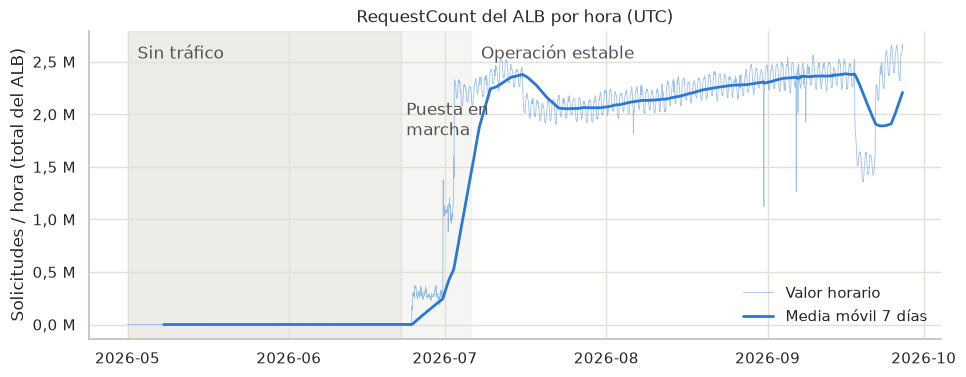

In [7]:
# Estilo de gráficos: grilla tenue, un solo color para la serie
AZUL = "#2a78d6"     # color de la serie
TINTA = "#52514e"    # líneas de referencia y textos secundarios
plt.rcParams.update({"axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.formatter.limits": (-9, 9)})   # evita la notación científica en los ejes

# Formato de números en convención española: punto para miles, coma para decimales
from matplotlib.ticker import FuncFormatter

def numero_es(x, decimales=0):
    texto = f"{x:,.{decimales}f}"                                        # formato inglés: 1,234.5
    return texto.replace(",", "_").replace(".", ",").replace("_", ".")  # convención española: 1.234,5

EJE_ES = FuncFormatter(lambda x, pos: numero_es(x, 0 if float(x).is_integer() else 1))
EJE_MILLONES = FuncFormatter(lambda x, pos: numero_es(x / 1e6, 1) + " M")
FORMATO_VALOR = EJE_MILLONES   # los valores de esta serie llegan a millones: se abrevian

def valor_es(x):
    return numero_es(x / 1e6, 2) + " M"

# Serie indexada por tiempo (definida también en la Etapa 2; se recalcula para que la sección sea autocontenida)
serie = df.set_index("period_start_utc")["value"].sort_index()
inicio_activo = serie[serie > 0].index.min()
activa = serie[serie.index >= inicio_activo]

# Medias semanales (semanas de lunes a domingo) del período activo
semanal = activa.resample("W-MON", label="left", closed="left").mean()
umbral = 0.9 * semanal.median()
inicio_estable = semanal[semanal >= umbral].index.min()
estable = serie[serie.index >= inicio_estable]

print("Medias semanales del período activo (semana que empieza el lunes):")
print(semanal.round(0).to_string())
print(f"\nMediana semanal: {semanal.median():,.0f}  ->  umbral (90 %): {umbral:,.0f}")
print("Inicio del período activo :", inicio_activo)
print("Inicio del período estable:", inicio_estable)
print(f"Horas: sin tráfico={len(serie[serie.index < inicio_activo])}, "
      f"puesta en marcha={len(activa[activa.index < inicio_estable])}, estable={len(estable)}")

# Serie completa con los períodos sombreados y media móvil de 7 días
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(serie.index, serie, color=AZUL, linewidth=0.6, alpha=0.45, label="Valor horario")
ax.plot(serie.index, serie.rolling(24 * 7).mean(), color=AZUL, linewidth=2, label="Media móvil 7 días")
ax.axvspan(serie.index.min(), inicio_activo, color="#e1e0d9", alpha=0.6)
ax.axvspan(inicio_activo, inicio_estable, color="#e1e0d9", alpha=0.3)
ax.text(serie.index.min(), serie.max() * 0.95, "  Sin tráfico", color=TINTA)
ax.text(inicio_activo, serie.max() * 0.80, " Puesta en\n marcha", color=TINTA, va="top")
ax.text(inicio_estable, serie.max() * 0.95, "  Operación estable", color=TINTA)
ax.set_title("RequestCount del ALB por hora (UTC)")
ax.set_ylabel("Solicitudes / hora (total del ALB)")
ax.yaxis.set_major_formatter(FORMATO_VALOR)
ax.legend(loc="lower right", frameon=False)
plt.show()

### 3.a — Variables numéricas: estadísticos descriptivos

In [8]:
# Estadísticos descriptivos de 'value': período activo vs. período estable
resumen = pd.DataFrame({"activo": activa.describe(), "estable": estable.describe()}).round(1)
print(resumen)
print()
print("Asimetría (skew)  activo:", round(activa.skew(), 2), "| estable:", round(estable.skew(), 2))

# Valores atípicos en el período estable según la regla IQR (fuera de Q1 - 1.5·IQR, Q3 + 1.5·IQR)
q1, q3 = estable.quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
atipicos = estable[(estable < lim_inf) | (estable > lim_sup)]
print(f"Límites IQR: [{lim_inf:,.0f} ; {lim_sup:,.0f}]  ->  atípicos: {len(atipicos)} "
      f"({len(atipicos) / len(estable):.1%} de las horas estables)")
print("Mayores valores:")
print(estable.nlargest(3))

          activo    estable
count     2313.0     1991.0
mean   2025469.8  2217536.4
std     607917.9   219844.6
min          0.0  1124716.0
25%    2052900.0  2120566.5
50%    2215041.0  2244131.0
75%    2341967.0  2362679.5
max    2664010.0  2664010.0

Asimetría (skew)  activo: -2.25 | estable: -1.36
Límites IQR: [1,757,397 ; 2,725,849]  ->  atípicos: 92 (4.6% de las horas estables)
Mayores valores:
period_start_utc
2026-09-26 21:00:00+00:00    2664010
2026-09-24 18:00:00+00:00    2659683
2026-09-24 20:00:00+00:00    2658853
Name: value, dtype: int64


### 3.b — Variable numérica: histograma de `value` (período estable)
`value` es la única variable numérica informativa. El histograma se hace sobre el período estable para que los ceros del arranque no deformen la distribución.

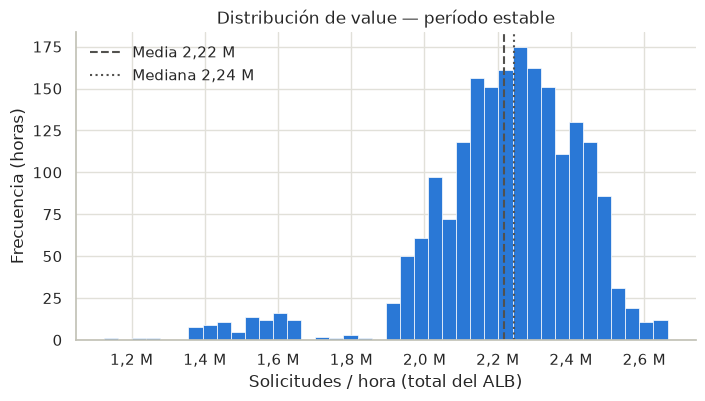

In [9]:
columna_numerica = "value"   # única variable numérica informativa del dataset

fig, ax = plt.subplots()
ax.hist(estable, bins=40, color=AZUL, edgecolor="white", linewidth=0.5)
ax.axvline(estable.mean(), color=TINTA, linestyle="--", linewidth=1.5, label=f"Media {valor_es(estable.mean())}")
ax.axvline(estable.median(), color=TINTA, linestyle=":", linewidth=1.5, label=f"Mediana {valor_es(estable.median())}")
ax.set_title(f"Distribución de {columna_numerica} — período estable")
ax.set_xlabel("Solicitudes / hora (total del ALB)")
ax.set_ylabel("Frecuencia (horas)")
ax.xaxis.set_major_formatter(FORMATO_VALOR)
ax.legend(frameon=False)
plt.show()

### 3.c — Variables temporales derivadas: perfil por hora del día y por día de la semana
La plantilla original (tabla de frecuencias de una **categórica**) no aplica: las tres columnas categóricas son constantes, así que su tabla tendría una sola fila. En una serie temporal, las "categorías" útiles son las del **calendario**: hora del día (0–23) y día de la semana (lunes–domingo). Son variables ordinales y cíclicas. Para cada categoría no interesa contar filas, porque todas tienen la misma cantidad de horas, sino mirar el **valor medio de `value`**.

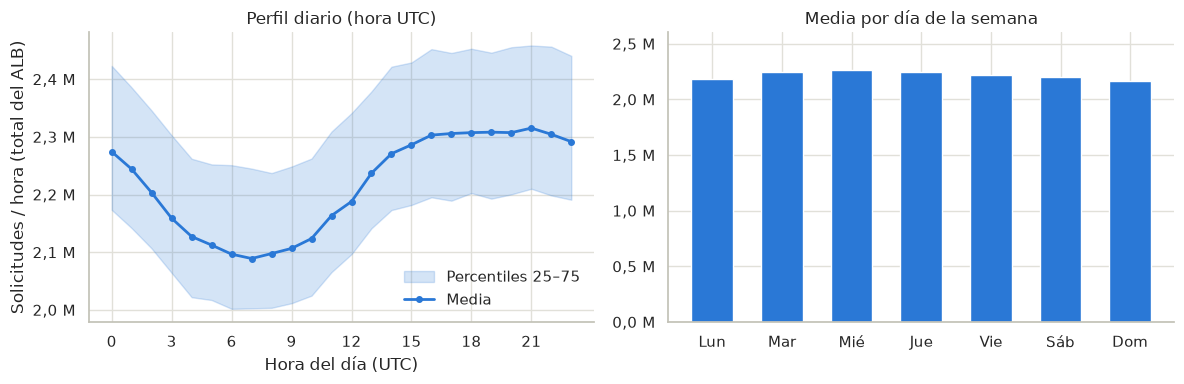

Hora de mínimo: 7 h UTC (2,089,056) | Hora de máximo: 21 h UTC (2,315,216) | Amplitud: 11%
Media por día: {'Lun': 2178663, 'Mar': 2245346, 'Mié': 2262923, 'Jue': 2249905, 'Vie': 2214698, 'Sáb': 2198939, 'Dom': 2168095}
Diferencia entre el día más alto y el más bajo: 4.4%


In [10]:
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
por_hora = estable.groupby(estable.index.hour)
media_hora = por_hora.mean()
p25_hora, p75_hora = por_hora.quantile(0.25), por_hora.quantile(0.75)
media_dia = estable.groupby(estable.index.day_of_week).mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.fill_between(media_hora.index, p25_hora, p75_hora, color=AZUL, alpha=0.2, label="Percentiles 25–75")
ax1.plot(media_hora.index, media_hora, color=AZUL, linewidth=2, marker="o", markersize=4, label="Media")
ax1.set_title("Perfil diario (hora UTC)")
ax1.set_xlabel("Hora del día (UTC)")
ax1.set_ylabel("Solicitudes / hora (total del ALB)")
ax1.set_xticks(range(0, 24, 3))
ax1.yaxis.set_major_formatter(FORMATO_VALOR)
ax1.legend(frameon=False)

ax2.bar(dias, media_dia.values, color=AZUL, width=0.6)
ax2.set_title("Media por día de la semana")
ax2.set_ylim(0, media_dia.max() * 1.15)
ax2.yaxis.set_major_formatter(FORMATO_VALOR)
plt.tight_layout()
plt.show()

print(f"Hora de mínimo: {media_hora.idxmin()} h UTC ({media_hora.min():,.0f}) | "
      f"Hora de máximo: {media_hora.idxmax()} h UTC ({media_hora.max():,.0f}) | "
      f"Amplitud: {media_hora.max() / media_hora.min() - 1:.0%}")
print("Media por día:", {d: round(v) for d, v in zip(dias, media_dia.values)})
print(f"Diferencia entre el día más alto y el más bajo: {media_dia.max() / media_dia.min() - 1:.1%}")

### 3.d — Dependencia temporal: autocorrelación y mapa día × hora
La plantilla original (matriz de correlación entre variables numéricas) no aplica: hay **una sola** variable numérica, así que la matriz sería de 1×1. En una serie temporal, la pregunta equivalente es cuánto se parece la serie **a sí misma desplazada en el tiempo**: la **autocorrelación** en el rezago *k* es la correlación entre `value(t)` y `value(t−k)`. Los rezagos clave son 1 hora (inercia), 24 horas (ciclo diario) y 168 horas (ciclo semanal).

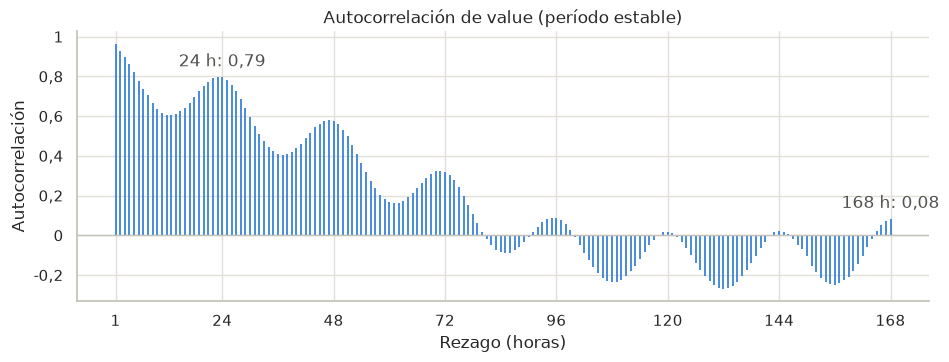

Autocorrelación en rezagos 1, 24 y 168: {1: 0.964, 24: 0.795, 168: 0.082}


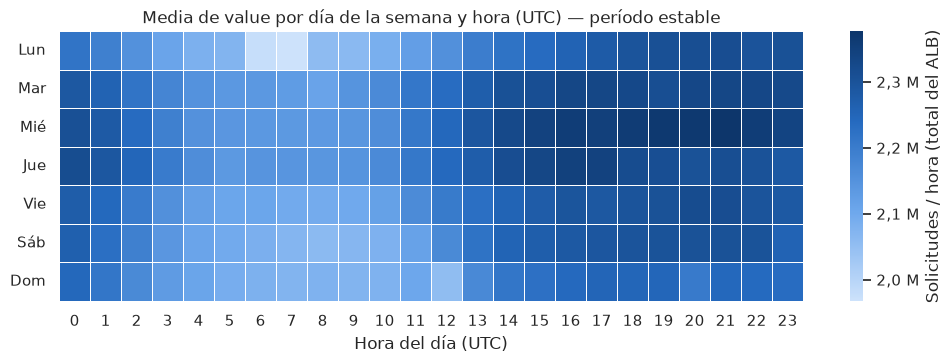

In [11]:
# Autocorrelación de la serie estable para rezagos de 1 a 168 horas
rezagos = range(1, 169)
acf = pd.Series([estable.autocorr(k) for k in rezagos], index=rezagos)

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.vlines(acf.index, 0, acf.values, color=AZUL, linewidth=1.2)
for k in (24, 168):
    ax.annotate(f"{k} h: {numero_es(acf[k], 2)}", (k, acf[k]), xytext=(0, 8), textcoords="offset points",
                ha="center", color=TINTA)
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_title("Autocorrelación de value (período estable)")
ax.set_xlabel("Rezago (horas)")
ax.set_ylabel("Autocorrelación")
ax.yaxis.set_major_formatter(EJE_ES)
ax.set_xticks([1, 24, 48, 72, 96, 120, 144, 168])
plt.show()
print("Autocorrelación en rezagos 1, 24 y 168:", {k: round(float(acf[k]), 3) for k in (1, 24, 168)})

# Mapa de calor: media de value por día de la semana (filas) y hora UTC (columnas)
from matplotlib.colors import LinearSegmentedColormap
azules = LinearSegmentedColormap.from_list("azules", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
tabla = (estable.to_frame("value")
         .assign(dia=estable.index.day_of_week, hora=estable.index.hour)
         .pivot_table(index="dia", columns="hora", values="value", aggfunc="mean"))
tabla.index = dias

fig, ax = plt.subplots(figsize=(12, 3.5))
sns.heatmap(tabla, cmap=azules, linewidths=0.5, linecolor="white",
            cbar_kws={"format": FORMATO_VALOR, "label": "Solicitudes / hora (total del ALB)"}, ax=ax)
ax.set_title("Media de value por día de la semana y hora (UTC) — período estable")
ax.set_xlabel("Hora del día (UTC)")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
plt.show()

### 3.e — Comparación con la serie por target (`RequestCountPerTarget`)

En el TP principal se analizó `RequestCountPerTarget`, que según AWS es el total de solicitudes del *target group* dividido por la cantidad de **targets sanos**. Si el balanceador atiende solo al servicio de tienda, el cociente

$$\frac{\text{RequestCount}}{\text{RequestCountPerTarget}}$$

aproxima la **cantidad promedio de targets sanos** en cada hora. **Advertencia:** este export de `RequestCount` no tiene dimensión `TargetGroup`. Si el ALB enrutara a otros *target groups*, ese tráfico también estaría en el numerador y el cociente sobreestimaría la cantidad de targets. Por eso se lo usa como **indicio** de cuánto cambia la capacidad, no como un conteo exacto.

Cociente RequestCount / RequestCountPerTarget (período estable):
count    1991.0
mean       21.4
std         2.4
min        14.9
25%        19.9
50%        21.0
75%        22.4
max        33.0
Mediana semanal del cociente:
period_start_utc
2026-07-06 00:00:00+00:00    26.1
2026-07-13 00:00:00+00:00    21.7
2026-07-20 00:00:00+00:00    20.7
2026-07-27 00:00:00+00:00    21.2
2026-08-03 00:00:00+00:00    21.8
2026-08-10 00:00:00+00:00    21.5
2026-08-17 00:00:00+00:00    20.5
2026-08-24 00:00:00+00:00    20.2
2026-08-31 00:00:00+00:00    19.7
2026-09-07 00:00:00+00:00    20.3
2026-09-14 00:00:00+00:00    19.4
2026-09-21 00:00:00+00:00    22.3
Freq: W-MON


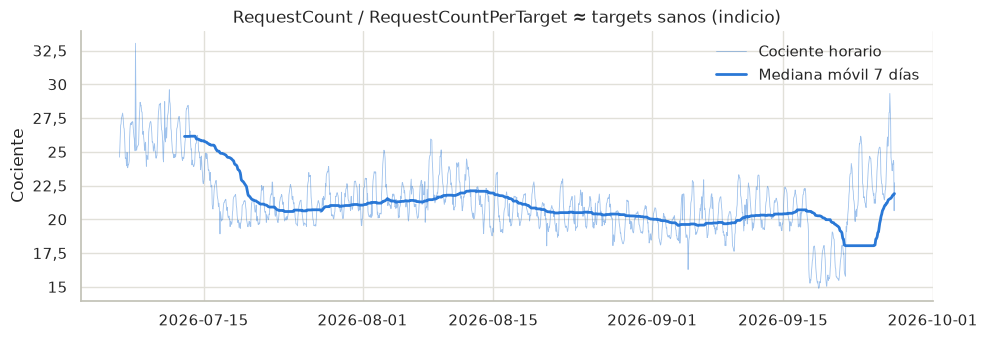

RequestCount (total)     18–21/09 vs. 11–14/09: -33.7%
RequestCountPerTarget    18–21/09 vs. 11–14/09: -18.2%
Cociente (≈ targets)     18–21/09 vs. 11–14/09: -19.0%


In [12]:
# Serie por target del mismo período (dataset del TP principal)
ruta_por_target = Path("data/store-service-request-count-per-target-hourly-since-2026-05-01.csv")
por_target = (pd.read_csv(ruta_por_target, parse_dates=["period_start_utc"])
              .assign(period_start_utc=lambda d: pd.to_datetime(d["period_start_utc"], utc=True))
              .set_index("period_start_utc")["value"].sort_index())

# Cociente horario en el período estable de esta serie (se excluyen horas con 0 en el denominador)
denominador = por_target[estable.index].replace(0, np.nan)
cociente = (estable / denominador).dropna()
print("Cociente RequestCount / RequestCountPerTarget (período estable):")
print(cociente.describe().round(1).to_string())
print("Mediana semanal del cociente:")
print(cociente.resample("W-MON", label="left", closed="left").median().round(1).to_string())

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(cociente.index, cociente, color=AZUL, linewidth=0.6, alpha=0.45, label="Cociente horario")
ax.plot(cociente.index, cociente.rolling(24 * 7).median(), color=AZUL, linewidth=2, label="Mediana móvil 7 días")
ax.set_title("RequestCount / RequestCountPerTarget ≈ targets sanos (indicio)")
ax.set_ylabel("Cociente")
ax.yaxis.set_major_formatter(EJE_ES)
ax.legend(loc="upper right", frameon=False)
plt.show()

# Caída del 18/09 al 21/09: variación de cada serie frente a la misma franja de la semana anterior
caida = slice("2026-09-18", "2026-09-21")
previa = slice("2026-09-11", "2026-09-14")
for nombre, s in [("RequestCount (total)", serie), ("RequestCountPerTarget", por_target)]:
    print(f"{nombre:<24} 18–21/09 vs. 11–14/09: {s[caida].mean() / s[previa].mean() - 1:+.1%}")
print(f"{'Cociente (≈ targets)':<24} 18–21/09 vs. 11–14/09: {cociente[caida].median() / cociente[previa].median() - 1:+.1%}")

### ¿Qué observar?

- En los **histogramas**: ¿la distribución es simétrica, sesgada, tiene varios picos? ¿Hay valores extremos (*outliers*)?
- En las **tablas de frecuencia**: ¿las categorías están balanceadas o hay una dominante?
- En la **correlación**: ¿hay pares de variables fuertemente relacionadas? ¿Eso tiene sentido en el dominio del problema?


### ✏️ Su respuesta — Etapa 3

**Hallazgos principales del EDA** (horas en UTC):

1. **Mismos tres regímenes, pero el tráfico total se estabiliza antes.** Con el mismo criterio del TP principal (umbral = 90 % de la mediana semanal = 1 976 654), la operación estable empieza el **06/07**, una semana antes que la serie por target (13/07). En la semana del 06/07 el total ya era de 2 330 191 solicitudes por hora en promedio, mientras que el promedio por target seguía subiendo: en esos días había **más targets** que después. El cociente de la sección 3.e lo muestra: unos 26 en julio frente a unos 21 desde agosto.
2. **La distribución tiene una cola izquierda por un evento puntual.** En el período estable, la media es de **2 217 536** y la mediana de **2 244 131** solicitudes por hora, con una asimetría de **−1,36**. La regla IQR marca **92 horas atípicas (4,6 %)**, todas bajas: 89 de ellas están entre el **18/09 y el 21/09**, cuando el tráfico total cayó un **33,7 %** respecto de los mismos días de la semana anterior. Hasta el 17/09 la asimetría es apenas de −0,58. También hay caídas aisladas el 31/08 (1 124 716) y el 06/09, en las mismas fechas que en la serie por target.
3. **Ciclo diario moderado.** El mínimo está a las **7 h UTC (2 089 056)** y el máximo a las **21 h UTC (2 315 216)**, una amplitud del **11 %**. En la serie por target la amplitud era del 26 %: el promedio por target **exagera** el ciclo diario respecto del tráfico real.
4. **Ciclo semanal débil.** Entre el día más bajo (domingo, 2 168 095) y el más alto (miércoles, 2 262 923) la diferencia es del **4,4 %**.
5. **La dependencia temporal es alta en horas, pero la semanal es frágil.** La autocorrelación vale **0,964** a 1 h y **0,795** a 24 h, pero solo **0,082** a 168 h. La caída del 18 al 21/09 rompe la comparación semana contra semana: si se calcula solo hasta el 17/09, la autocorrelación a 168 h sube a **0,572** y la de 24 h a **0,835**.

**Comparación con la serie por target (3.e):** el cociente `RequestCount / RequestCountPerTarget` tiene una mediana de **21,0** y va de **14,9 a 33,0**: no es constante. Durante la caída del 18–21/09 el tráfico total bajó un **33,7 %**, pero el promedio por target solo un **18,2 %**, porque el cociente (≈ targets) también bajó un **19,0 %**. Es decir, la capacidad se redujo junto con el tráfico. Esto confirma con datos el riesgo señalado en el TP principal: la métrica por target depende de la cantidad de targets y **subestima** la magnitud de los cambios de tráfico.

# Etapa 4 — Propuesta de modelo

A partir de lo que vieron, propongan **qué tipo de modelo** se podría construir con este dataset. La pregunta guía es: *¿qué tipo de problema de aprendizaje automático representan estos datos?*

| Si... | Entonces el tipo de modelo es... |
|---|---|
| Hay un **target categórico** (clase/etiqueta) | **Clasificación** |
| Hay un **target numérico continuo** | **Regresión** |
| **No hay target** y se buscan grupos | **Agrupamiento (*clustering*)** |
| Los datos son una **serie temporal** | **Pronóstico (*forecasting*)** |

> **No tienen que entrenar el modelo.** Solo deben **justificar** qué tipo correspondería y qué variable sería el *target* (si lo hubiera).


### Evidencia para la propuesta: líneas base ingenuas

Esto **no es entrenar un modelo**: no se ajusta ningún parámetro. Se mide qué tan bien se predeciría cada hora copiando un valor del pasado: el de 1 hora antes, el de 24 horas antes (misma hora del día anterior) y el de 168 horas antes (misma hora de la semana anterior). Sirve para dos cosas: medir cuánta información aporta cada rezago, y fijar el error que cualquier modelo propuesto tendría que superar.

- **MAE** (error absoluto medio): error típico en solicitudes por hora.
- **MAPE** (error porcentual absoluto medio): el mismo error expresado en porcentaje del valor real.

Se evalúan las dos últimas semanas completas de la serie.

In [13]:
# Período de evaluación: las dos últimas semanas completas (lunes a domingo)
eval_desde, eval_hasta = pd.Timestamp("2026-09-07", tz="UTC"), pd.Timestamp("2026-09-20 23:00", tz="UTC")
real = serie[eval_desde:eval_hasta]

filas = []
for rezago, nombre in [(1, "Hace 1 hora"), (24, "Misma hora, día anterior"), (168, "Misma hora, semana anterior")]:
    prediccion = serie.shift(rezago)[eval_desde:eval_hasta]
    error = (real - prediccion).abs()
    filas.append({"línea base": nombre, "rezago (h)": rezago,
                  "MAE": round(error.mean()), "MAPE (%)": round(100 * (error / real).mean(), 1)})

lineas_base = pd.DataFrame(filas).set_index("línea base")
print(f"Período evaluado: {eval_desde:%Y-%m-%d} a {eval_hasta:%Y-%m-%d} ({len(real)} horas)")
lineas_base

Período evaluado: 2026-09-07 a 2026-09-20 (336 horas)


,rezago (h),MAE,MAPE (%)
línea base,,,
Hace 1 hora,1,27496,1.3
"Misma hora, día anterior",24,100916,5.6
"Misma hora, semana anterior",168,225533,13.8


### ✏️ Su respuesta — Etapa 4

**Tipo de modelo propuesto:** **pronóstico de series temporales (*forecasting*)**, planteado como regresión sobre el tiempo: dado el historial hasta la hora *t*, predecir el tráfico total en *t+1 … t+h*, con horizonte de horas a pocos días.

**Variable objetivo (si aplica):** `value` (`RequestCount`), es decir, las solicitudes totales que procesará el ALB en cada hora futura.

**Variables de entrada (features) que usarían:**
- **Calendario:** hora del día (codificada de forma cíclica con seno y coseno), día de la semana y si es fin de semana.
- **Rezagos:** valor de hace 1 h y de hace 24 h. El de 168 h se incluiría solo junto con un indicador de eventos, porque su relación con el presente es inestable.
- **Ventanas móviles:** media de las últimas 24 h y de los últimos 7 días, para seguir el nivel.
- **Indicador de eventos o anomalías**, por ejemplo para marcar el período del 18 al 21/09. Así el modelo no aprende esa caída como si fuera un patrón estacional.
- Se descartan las columnas constantes, la vacía (`target_group`) y `period_end_utc`. Se usa el período estable desde el 06/07.

**Justificación:**
- El target es un **conteo numérico ordenado en el tiempo** y se quiere anticipar su valor futuro, así que corresponde *forecasting*. No es **clasificación** (no hay clases) ni **clustering** (no se buscan grupos).
- **Líneas base** en las dos últimas semanas completas: hace 1 h, **MAPE 1,3 %**; mismo horario del día anterior, **5,6 %**; mismo horario de la semana anterior, **13,8 %**. El rezago semanal es el peor porque esas dos semanas incluyen la caída del 18 al 21/09. Esto refuerza que la *feature* clave es el **ciclo diario** combinado con el **nivel reciente**.
- **Meta:** con un horizonte de 24 h, un modelo debería bajar del **5,6 %** del pronóstico ingenuo del día anterior.
- **Por qué esta métrica es mejor target que `RequestCountPerTarget`:** mide la demanda real sin pasar por la cantidad de targets. Ese denominador cambió hasta un 19 % en una misma semana (sección 3.e) y depende de las decisiones del propio *autoscaling*.
- **Modelos candidatos:** *gradient boosting* sobre las *features* anteriores; como alternativas, SARIMA (estacionalidad de 24) o Prophet, que admite días especiales.

# Etapa 5 — Uso previsto

Por último, pongan el modelo en contexto. Un modelo no se construye en el vacío: sirve para **ayudar a tomar una decisión**.


### ✏️ Su respuesta — Etapa 5

**¿Para qué se usaría el modelo?** Para **pronosticar la demanda total** que llegará al balanceador y, a partir de ella, calcular cuántos targets se necesitan: **targets necesarios ≈ tráfico pronosticado ÷ capacidad por target**. Esa capacidad se obtiene de pruebas de carga o de la propia historia: en el TP principal, el promedio estable de `RequestCountPerTarget` fue de unas 106 000 solicitudes por target y hora. A diferencia del TP principal, el pronóstico ya no depende del número de targets, así que se puede usar para **decidir** ese número sin crear un circuito de retroalimentación.

**¿Quién lo usaría?** El equipo de **infraestructura / SRE** que opera el balanceador y el *autoscaling*. También el área de **costos de nube** y, para el detector de anomalías, el equipo de **guardia** (*on-call*).

**¿Qué decisión ayudaría a tomar?**
- **Escalado predictivo.** Fijar con anticipación el mínimo de targets para el pico de las 21 h UTC. Con un ciclo diario del 11 % en el tráfico total, el margen a cubrir es menor que el 26 % que sugería la métrica por target.
- **Detección de incidentes.** La caída del **33,7 %** del 18 al 21/09 duró unos cuatro días. Un pronóstico con intervalo de confianza habría marcado la primera hora fuera de rango, y alguien podría haber investigado si era un incidente, un cambio en un cliente o un problema de enrutamiento.
- **Planificación de capacidad.** La tendencia de julio a septiembre, con medias semanales que suben de 2,06 a 2,37 millones de solicitudes por hora, sirve para estimar el crecimiento del mes siguiente.

**Riesgos o consideraciones éticas:**
- **Puede haber otro tráfico.** El export no tiene dimensión `TargetGroup`, así que si el ALB enruta a otros servicios, su tráfico está incluido y el pronóstico del servicio de tienda quedaría sobreestimado. Antes de usarlo habría que exportar `RequestCount` con la dimensión `LoadBalancer, TargetGroup`.
- **Causa desconocida de la caída de septiembre.** No sabemos si fue un incidente, un cambio de negocio o un problema de medición. Si fue un incidente, entrenar con esos días sin marcarlos le enseñaría al modelo que esa caída es normal.
- **Historia corta.** Son unos 2,7 meses de operación estable (1991 horas), sin estacionalidad anual ni fechas comerciales.
- **Costo asimétrico.** Subestimar la demanda degrada el servicio para los clientes; sobreestimarla solo cuesta dinero. Conviene mantener un margen de seguridad y el *autoscaling* reactivo como respaldo.
- **Datos sensibles.** Son conteos agregados, sin datos personales, pero incluyen identificadores internos de la infraestructura de producción que no deberían publicarse fuera del ámbito académico.

# Declaración de uso de IA

Este notebook se desarrolló con asistencia de un agente de inteligencia artificial, bajo la dirección del estudiante.

| Aspecto | Detalle |
|---|---|
| **Herramienta** | Claude Code (agente de Anthropic que opera desde la terminal) |
| **Modelo** | Claude Opus 5.5 (`claude-opus-5-5`) |
| **Marco de trabajo** | Desarrollo guiado por especificaciones (*Spec-Driven Development*, SDD) con **OpenSpec 2.0.0** (`@fission-ai/openspec`), esquema `spec-driven` |
| **Entorno reproducible** | `uv` (Python 3.12, dependencias fijadas en `uv.lock`) |
| **Fecha** | 16/11/2026 |

**Cómo se trabajó.** Cada parte del trabajo se planteó como un *cambio* de OpenSpec con cuatro artefactos: propuesta (por qué), especificación (qué debe cumplirse, con escenarios verificables), diseño (cómo y con qué criterio) y tareas (pasos, cada uno con su verificación). El estudiante aprobó cada cambio antes de implementarlo. Al cerrarse, cada cambio se archivó y sus requisitos se consolidaron en `openspec/specs/`. Los cambios completos, con sus decisiones y criterios, están en `openspec/changes/archive/`.

**Cambios que afectan a este notebook:**
- `setup-uv-environment`: entorno de Python con `uv`.
- `analyze-alb-request-count`: copia del TP principal aplicada a `RequestCount` y comparación con la serie por target.
- `format-chart-numbers-and-ai-declaration`: formato de números en los gráficos (millones abreviados) y esta declaración.

El notebook base, `TP_Analisis_de_Dataset_v3.ipynb`, se construyó con los cambios `load-store-traffic-dataset` a `define-store-traffic-model-use` y `clarify-request-count-per-target`.

**Qué hizo el agente:** escribió el código de las celdas, ejecutó el notebook, redactó las respuestas a partir de las salidas ejecutadas y redactó los artefactos de OpenSpec. Las cifras de las respuestas se verificaron contra las salidas del propio notebook, y la definición de las métricas, contra la documentación de AWS.

**Qué hizo el estudiante:** eligió y aportó los datos; definió el flujo de trabajo (OpenSpec, un cambio por etapa, `uv`) y las restricciones del proyecto (artefactos en español, decisiones respaldadas por criterios y datos, pasos reproducibles); cuestionó la interpretación de la métrica `RequestCountPerTarget`; pidió la variante con `RequestCount` y los ajustes de presentación; y aprobó cada cambio.

# Cierre y entrega

Antes de entregar, verifiquen que:

- [x] Eligieron un dataset y lo cargaron correctamente (Etapa 1).
- [x] Identificaron y clasificaron los tipos de datos (Etapa 2).
- [x] Ejecutaron el EDA con las herramientas adecuadas al tipo de datos (Etapa 3).
- [x] Propusieron y justificaron un tipo de modelo (Etapa 4).
- [x] Explicaron el uso previsto y sus consideraciones (Etapa 5).
- [x] **Todas las celdas están ejecutadas** y sus salidas son visibles.

**Para entregar:** `Archivo → Descargar → Descargar .ipynb`, o compartan el enlace de Colab con permiso de lectura.

---

*Fundamentos de Aprendizaje Automático · 2026 · Universidad Austral*
